In [158]:
import numpy as np
from pathlib import Path
import timeit
import pandas as pd
import sys
sys.path.insert(1, '../')
import util
from util.dynamics import temp_response, environmental_update
from util.plot import lighten_color

import scipy as sp
import matplotlib.pyplot as plt
# import tqdm
from matplotlib.lines import Line2D

import tqdm
import seaborn as sns
from scipy.optimize import fsolve
import os
from scipy.optimize import curve_fit

import matplotlib as mpl
import xarray as xr

def moving_avg(temps,N=20):
    moving_avg = np.cumsum(temps)
    moving_avg[N:] -= moving_avg[:-N]
    moving_avg[N:] /= N
    moving_avg[:N] /= np.arange(1,N+1)
    return moving_avg

def PA_compliant(temps):
    if np.max(temps) > 2:
        return False
    elif np.mean(temps[-20:]) <= 1.5:
        return True
    else:
        return False

def OS_ref(temps,ref=1.5,window=1):
    stat_yrs = np.where(np.abs(df[s].to_numpy()-ref)<=0.05)[0]
    if len(stat_yrs) < 2:
        return False
    elif np.diff(stat_yrs).max()>window:
        return True
    else:
        return False 
    return 

def OS_model(t, *args):
    T_0,T_peak,T_os,t_up,t_plat,t_down=args
    out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up
    out = np.concatenate([out,[T_peak]*len(t[(t_up<t)&(t<=t_up+t_plat)])])
    out = np.concatenate([out, T_peak - (t[(t_up+t_plat<t)&(t<=t_down+t_up+t_plat)]-t_up-t_plat)*(T_peak-T_os)/(t_down)])
    return np.concatenate([out, [T_os]*(len(t)-len(out))])

# Using PROVIDE Project scenarios
Robin Lamboll, Joeri Rogelj, & Carl-Friedrich Schleussner. (2025). Scenario emissions and temperature data for PROVIDE project (v1.3.0) [Data set]. Zenodo. https://doi.org/10.5281/zenodo.11108741

https://pure.iiasa.ac.at/id/eprint/18130/1/essoar.10511875.2.pdf for description

https://zenodo.org/records/11108741 for actual data set

In [2]:
folder = '../../Data/PROVIDE 2025/'
cols = list(pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',nrows=1))
df = pd.read_csv(folder+'post-2100_inc_redundanttier1_temperature_summary.csv',
                 usecols = [c for c in cols if (c != 'quantile') and (c!= 'atomic_scen')]).set_index('scenario').T
df.index.names=['year']
# df=df.rename(columns={'scenario':''})
scenarios = df.columns.values

In [3]:
print(scenarios)

['CurPol_SAP' 'CurPol_OS_1.5C' 'ModAct_OS_1.5C' 'ModAct_OS_1C'
 'ModAct_SAP' 'ssp534-over' 'Neg_SAP' 'GS_NZGHG' 'Ren_NZCO2' 'Neg_NZGHG'
 'Ref_1p5' 'Neg_OS_0C' 'LD_NZGHG' 'SP_NZGHG' 'ssp119']


# Using GTPR2025 TEs

In [34]:
df_TEs = pd.read_excel('../../Data/TEsummary.xlsx',header=[0],index_col=0,sheet_name='GTPR25')
df_TEs[['Threshold (°C) – Min.', 
        'Threshold (°C) – Est.', 
        'Threshold (°C) – Max.']] = df_TEs[['Threshold (°C) – Min.', 
                                            'Threshold (°C) – Est.', 
                                            'Threshold (°C) – Max.']].interpolate(method='linear', axis=1, limit_direction='backward')
T_lim = df_TEs['Threshold (°C) – Est.'].to_numpy() # Critical threshold for tipping
betas = df_TEs['Beta (1/°C)'].to_numpy() # Logistic parameter (temp. sensitivity)
q_c = 1/(1+df_TEs['Collapse (years)'].to_numpy()) # collapse leverage
q_r = 1/(1+df_TEs['Recovery (years)'].to_numpy())

# Loading pre-saved interaction matrices
len_sample=500
A = [np.loadtxt('../../Data/Interaction matrices/A_%s.csv'%r) for r in range(len_sample)]

In [162]:
print(df_TEs.index.to_numpy())

['AMAZ' 'AMOC' 'ASI' 'ENSO' 'GIS' 'PERM' 'REEF' 'WAIS' 'WAM']


# 1D perturbations around baseline

## Historical data to burn in and get initial condition for 2015

In [37]:
years_burn_in = np.arange(1850,2016) # up to and including 2015
no_burn_years = len(years_burn_in)
pc_burn = np.ones((no_burn_years,len(df_TEs)))
pc_burn *= q_c
pr_burn = np.ones((no_burn_years,len(df_TEs)))
pr_burn *= q_r
for t in years_burn_in-1850:
    pc_burn[t,:] *= temp_response(temp[t], T_lim, betas)
    pr_burn[t,:] *= (1-temp_response(temp[t], T_lim, betas))

D_burn = np.zeros((len_sample,len(df_TEs)))
D_burn_noint = np.zeros(len(df_TEs))

In [39]:
for r in tqdm.tqdm(range(len_sample)):
    for t in range(1,no_burn_years):
        D_burn[r,:] = environmental_update(D_burn[r,:],
                                           A[r],
                                           pc=pc_burn[t,:],
                                           pr=pr_burn[t,:])
for t in tqdm.tqdm(range(1,no_burn_years)):
    D_burn_noint = environmental_update(D_burn_noint,
                                        np.zeros((len(df_TEs),len(df_TEs))),
                                        pc=pc_burn[t,:],
                                        pr=pr_burn[t,:])

100%|██████████████████████████████████████| 165/165 [00:00<00:00, 43608.08it/s]


## 1D perturbations around popt

In [247]:
scenarios

array(['CurPol_SAP', 'CurPol_OS_1.5C', 'ModAct_OS_1.5C', 'ModAct_OS_1C',
       'ModAct_SAP', 'ssp534-over', 'Neg_SAP', 'GS_NZGHG', 'Ren_NZCO2',
       'Neg_NZGHG', 'Ref_1p5', 'Neg_OS_0C', 'LD_NZGHG', 'SP_NZGHG',
       'ssp119'], dtype=object)

Text(0.5, 0, 'Year')

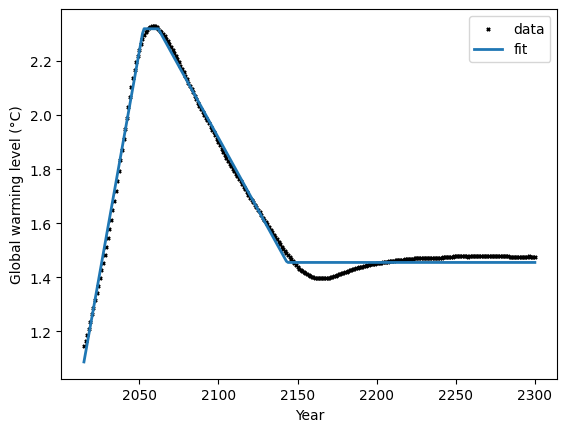

In [520]:
baseline = 'ssp534-over'
temp = df[baseline].to_numpy()
t_ref=2015
T_ref=temp[t_ref-1850]
T_max=temp.max()
xdata = np.arange(t_ref,2301)-t_ref
ydata=temp[t_ref-1850:]
popt, pcov = curve_fit(OS_model, xdata, ydata,
                       p0=[T_ref, T_max, temp[-1], (T_max-T_ref)/0.01, 10 ,(temp.max()-T_ref)/0.01],
                       bounds = ([T_ref-0.5, T_max-0.5, temp[-1]-0.5, 10, 0, 10],
                                 [T_ref+0.5, T_max+0.5, temp[-1]+0.5, len(ydata), 100, len(ydata)]) )
plt.scatter(xdata+t_ref,ydata,marker='x',s=5,c='k',label='data')
plt.plot(xdata+t_ref,OS_model(xdata,*popt),label='fit',lw=2)
plt.legend()
plt.ylabel('Global warming level (°C)')
plt.xlabel('Year')

In [521]:
popt

array([ 1.08741336,  2.31898889,  1.45509682, 37.55081547,  9.41345856,
       81.42360068])

In [522]:
T_0s = np.arange(0,2.5,step=0.1)
T_peaks = np.arange(0,5,step=0.1)
T_oss = np.arange(0,2.5,step=0.1)

# t_ups = np.arange(50,151,step=5)
# t_plats = np.arange(0,101,step=5)
# t_downs = np.arange(100,201,step=5)

t_ups = np.arange(0,201,step=10)
t_plats = np.arange(0,201,step=10)
t_downs = np.arange(0,201,step=10)

pars = [T_0s, T_peaks, T_oss, t_ups, t_plats, t_downs]

years = np.arange(2015,2301)
no_years=len(years)

pcs = [np.ones((len(p),no_years,len(df_TEs)))*q_c.reshape((1,1,len(df_TEs))) for p in pars]
prs = [np.ones((len(p),no_years,len(df_TEs)))*q_r.reshape((1,1,len(df_TEs))) for p in pars]

temps = [np.zeros((len(pars[i]),no_years)) for i in range(len(popt))]
for i in range(len(popt)):
    PAR = np.copy(popt)
    for j,p_j in enumerate(pars[i]):
        PAR[i] = p_j
        temps[i][j,:] = OS_model(xdata,*PAR)
        for t in range(no_years):
            pcs[i][j,t,:] *= temp_response(temps[i][j,t], T_lim, betas)
            prs[i][j,t,:] *= 1-temp_response(temps[i][j,t], T_lim, betas)

/tmp/ipykernel_200025/950359195.py:52: RuntimeWarning: invalid value encountered in divide
  out = T_0 + t[t<=t_up]*(T_peak-T_0)/t_up


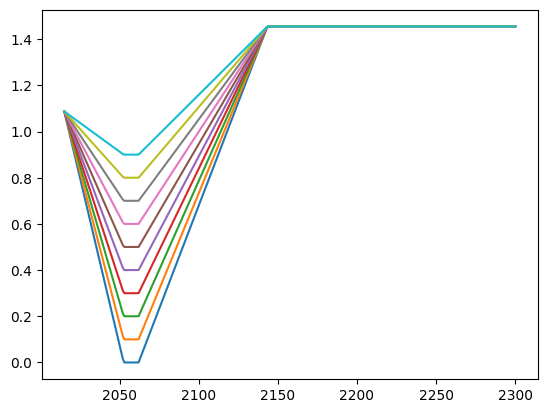

In [530]:
# for i in range(10):
#     plt.plot(years,pcs[0][i,:,5])
for i in range(10):
    plt.plot(years,temps[1][i,:])

In [524]:
years = np.arange(2015,2301)
no_years=len(years)
D = [np.zeros((len(pars[i]),len_sample,len(df_TEs),no_years)) for i in range(len(popt))]
D_noint = [np.zeros((len(pars[i]),len(df_TEs),no_years)) for i in range(len(popt))]

for i in range(len(popt)):
    for r in range(len_sample):
        D[i][:,r,:,0] = D_burn[r,:]
    D_noint[i][:,:,0] = D_burn_noint[:]

In [525]:
for i in range(len(popt)):
    for j in tqdm.tqdm(range(len(pars[i]))):
        for t in range(1,no_years):
            D_noint[i][j,:,t] = environmental_update(D_noint[i][j,:,t-1],
                                                     np.zeros((len(df_TEs),len(df_TEs))),
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])
            for r in range(len_sample):
                D[i][j,r,:,t] = environmental_update(D[i][j,r,:,t-1],A[r],
                                                     pc=pcs[i][j,t,:],pr=prs[i][j,t,:])

100%|███████████████████████████████████████████| 21/21 [00:18<00:00,  1.12it/s]


## Saving simulations as .zarr

In [514]:
folder = '../../Data/Simulations/Overshoots/perturb_around_baseline/'+baseline+'/'
if not os.path.exists(folder):
    os.makedirs(folder)

par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   

In [515]:
for i in range(len(popt)):
    attrs = {par_files[j]: popt[j] for j in range(len(popt)) if j!=i}
    attrs['description']="Risk of being in the degraded state, as parameter, %s, is varied."%(par_files[i])
    for j in range(len(popt)):
        if j != i:
            description += par_files[j] + ' = ' + str(popt[j]) + "\n"
    ds = xr.Dataset(
        data_vars = dict(
            risk = (['parameter', 'interaction_mat', 'tipping_element', 'year'],D[i]), 
            risk_noint = (['parameter', 'tipping_element', 'year'],D_noint[i])
        ), 
        coords = dict(
            parameter = pars[i], 
            interaction_mat=np.arange(len_sample), 
            tipping_element=df_TEs.index.to_numpy(),
            year=years
        ), 
        attrs=attrs,
    )
    ds.to_zarr(folder+par_files[i]+'.zarr',mode='w');
    # ds.to_netcdf(folder+par_files[i]+'.nc',mode='w');

/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Zarr format 3 specification. It may not be supported by other zarr implementations and may change in the future.
  warnings.warn(
/home/jbara/Code/my-venv/lib/python3.12/site-packages/zarr/api/asynchronous.py:247: ZarrUserWarning: Consolidated metadata is currently not part in the Za

In [383]:
ds.nbytes

216654960

In [245]:
ds

<xarray.Dataset> Size: 217MB
Dimensions:          (parameter: 21, sample: 500, tipping_element: 9, year: 286)
Coordinates:
  * parameter        (parameter) int64 168B 50 55 60 65 70 ... 135 140 145 150
  * sample           (sample) int64 4kB 0 1 2 3 4 5 ... 494 495 496 497 498 499
  * tipping_element  (tipping_element) object 72B 'AMAZ' 'AMOC' ... 'WAIS' 'WAM'
  * year             (year) int64 2kB 2015 2016 2017 2018 ... 2298 2299 2300
Data variables:
    risk             (parameter, sample, tipping_element, year) float64 216MB ...
    risk_noint       (parameter, tipping_element, year) float64 432kB 4.526e-...
Attributes:
    temp_0:       1.1481431369841522
    temp_peak:    1.5226249995103758
    temp_os:      1.0003794520617886
    time_up:      16.904572716974624
    time_plat:    19.431257052629118
    description:  Risk of being in the degraded state, as parameter, time_dow...

In [183]:
attrs = {par_files[j]: popt[j] for j in range(len(popt)) if j!=i}
attrs['description']="Risk of being in the degraded state, as parameter, %s, is varied."%(par_files[i])
print(attrs)

{'temp_peak': np.float64(3.3020667098240453), 'temp_os': np.float64(1.5042200000682613), 'time_up': np.float64(103.28176816128983), 'time_plat': np.float64(3.4404362899460215), 'time_down': np.float64(163.72772189035612), 'description': 'Risk of being in the degraded state, as parameter, temp_0, is varied.'}


## Plotting

In [ ]:
baseline = 'ssp119'
folder = '../../Data/Simulations/Overshoots/perturb_around_baseline/'+baseline+'/'
par_files = ['temp_0','temp_peak','temp_os',
             'time_up','time_plat','time_down']   
D = [xr.open_zarr(folder+par_files[i]+'.zarr').as_numpy()

In [198]:
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.cm import ScalarMappable

In [204]:
df_TEs.index.values

array(['AMAZ', 'AMOC', 'ASI', 'ENSO', 'GIS', 'PERM', 'REEF', 'WAIS',
       'WAM'], dtype=object)

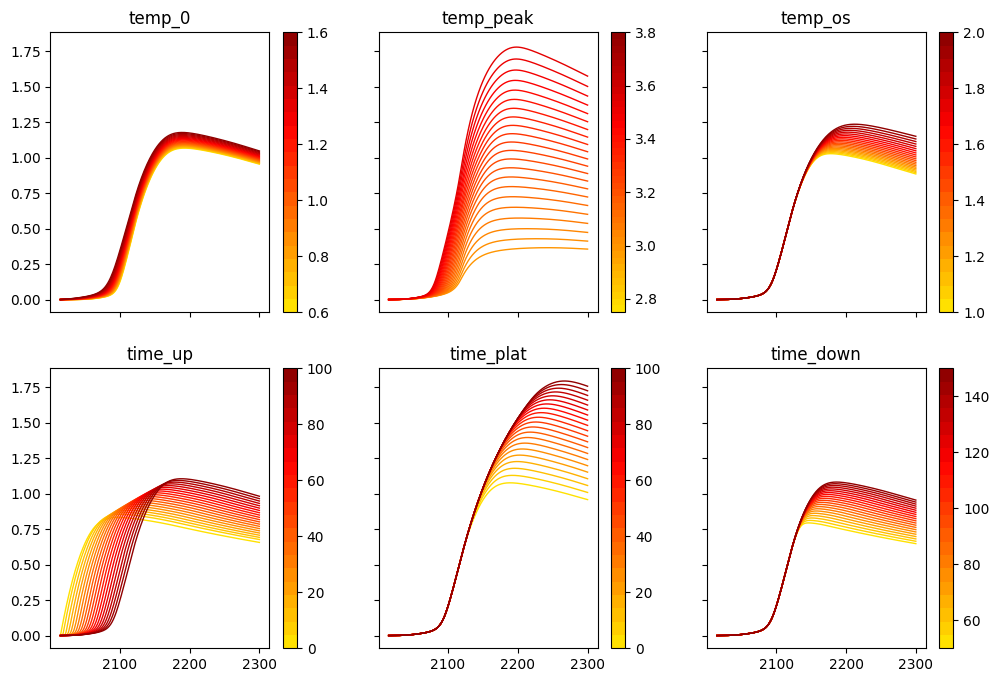

In [257]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,D[i][j,:,:,:].mean(axis=0).sum(axis=0) - D[i][j,:,-3,:].mean(axis=0),c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

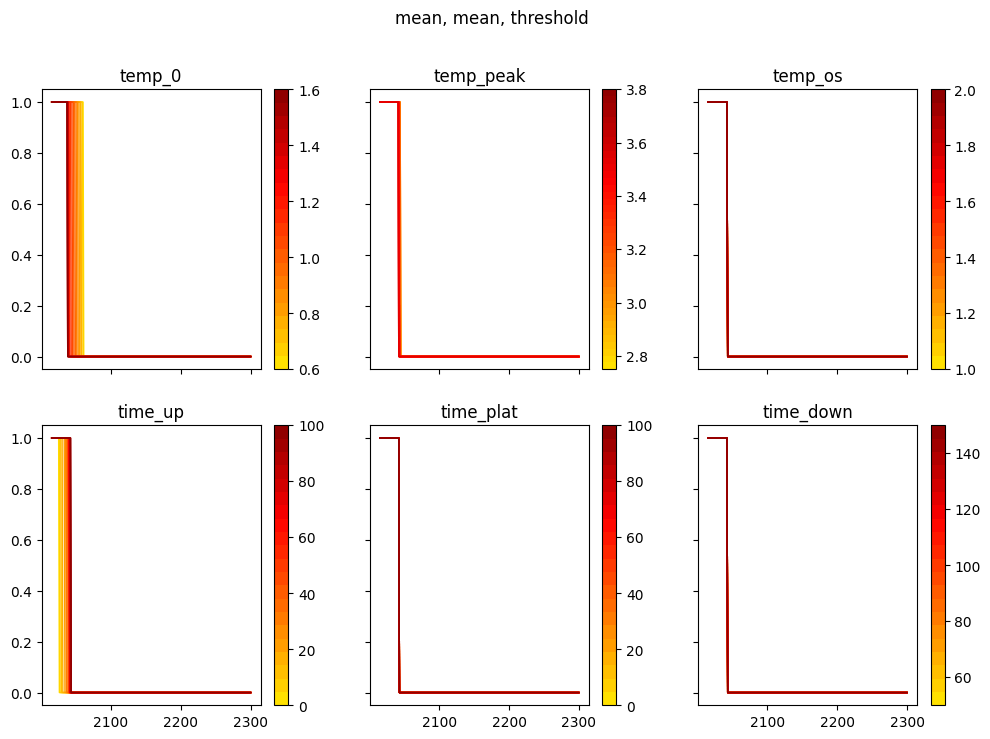

In [270]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
plt.suptitle("mean, mean, threshold")
sos_threshold=0.1
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,
                           (D[i][j,:,:,:].mean(axis=0).mean(axis=0))<=sos_threshold,
                            c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

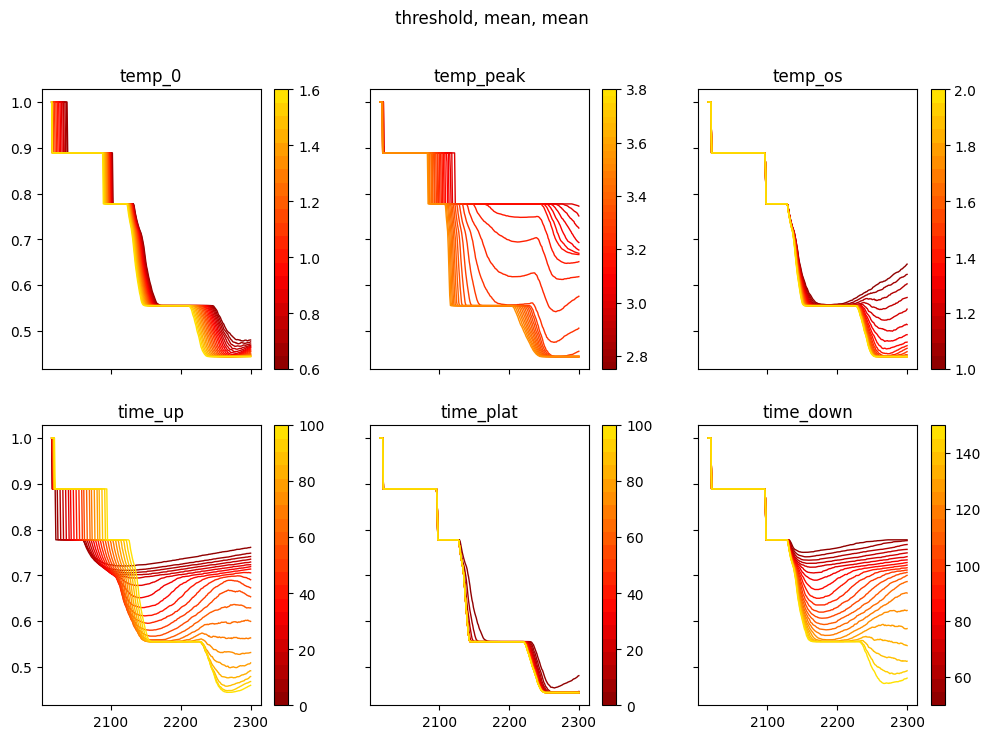

In [271]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
sos_threshold=0.1
plt.suptitle("threshold, mean, mean")
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))#[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,
                           (D[i][j,:,:,:]<=sos_threshold).mean(axis=0).mean(axis=0),c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

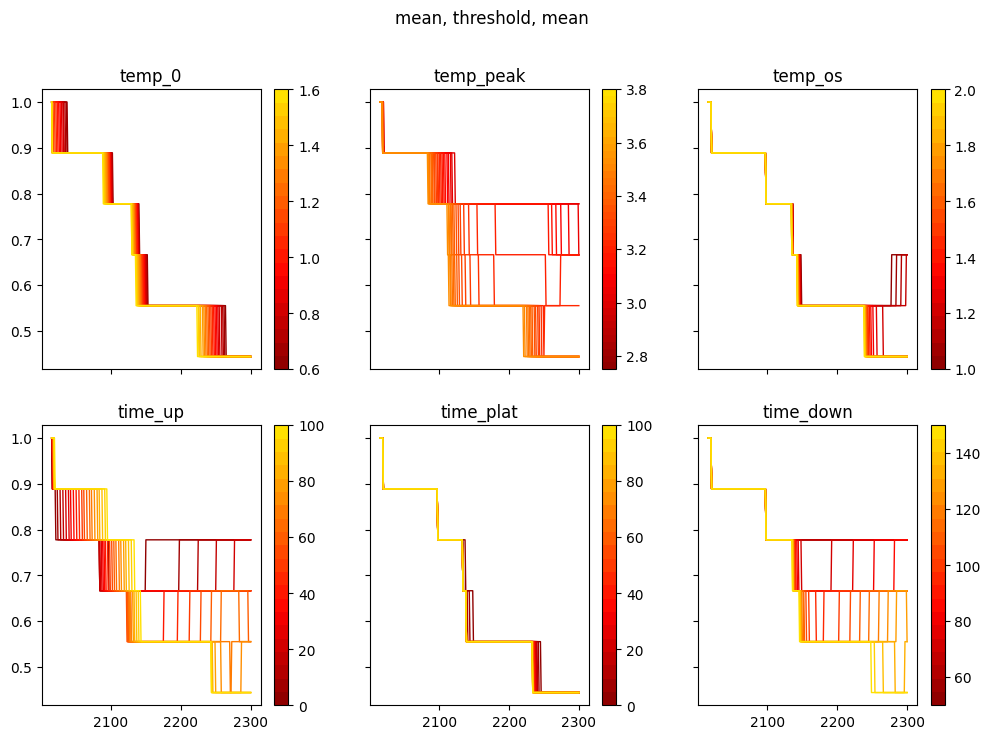

In [272]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=True,sharey=True)
sos_threshold=0.1
plt.suptitle("mean, threshold, mean")
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    # a,b=0,20
    if i == 1:
        a,b = 9,31
    else:
        a,b=0,21
    colors = plt.cm.hot(np.linspace(0.2,0.7,len(pars[i])))#[::-1]
    cmap = LinearSegmentedColormap.from_list('my_cmap', colors, N=colors.shape[0])
    for j in range(a,b):#len(pars[i])):
        # axs[i//3,i%3].plot(years,D_noint[i][j,:,:].sum(axis=0),c='k',lw=0.5)
        axs[i//3,i%3].plot(years,
                           (D[i][j,:,:,:].mean(axis=0)<=sos_threshold).mean(axis=0),c=colors[j,:],lw=1)
    fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

In [274]:
D[0].shape

(21, 500, 9, 286)

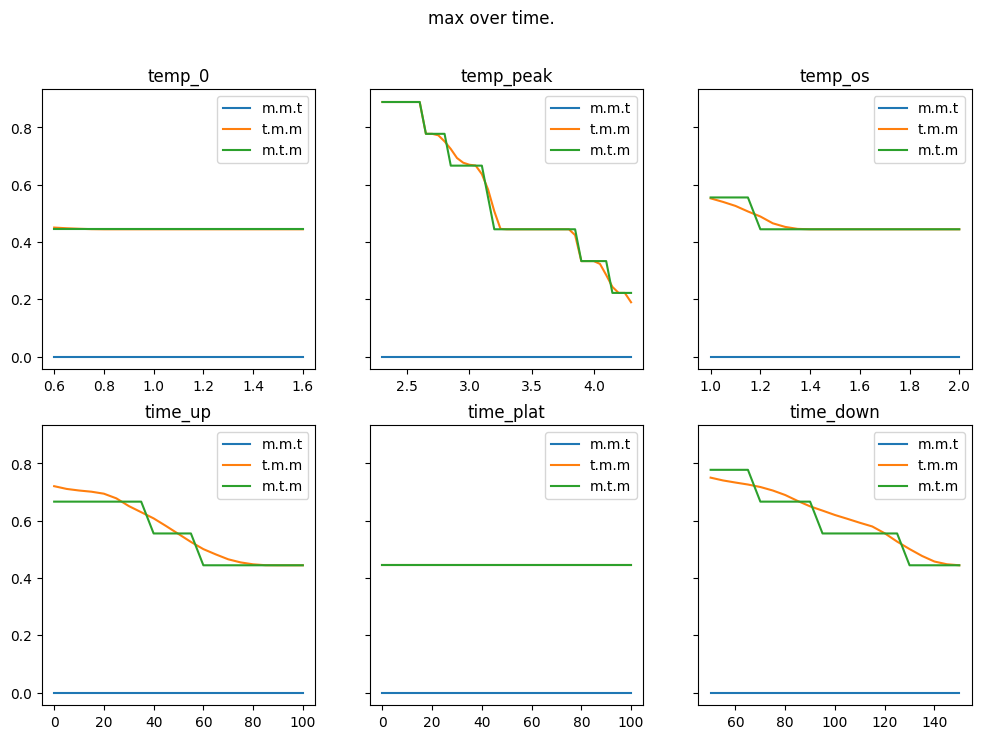

In [283]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=False,sharey=True)
sos_threshold=0.1
fig.suptitle("max over time.")
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])
    axs[i//3,i%3].plot(pars[i],
                       D[i].max(axis=-1).mean(axis=(1,2)) <=sos_threshold,label='m.m.t')
    axs[i//3,i%3].plot(pars[i],
                       (D[i].max(axis=-1)<=sos_threshold).mean(axis=(1,2)),label='t.m.m')
    axs[i//3,i%3].plot(pars[i],
                       (D[i].max(axis=-1).mean(axis=1)<=sos_threshold).mean(axis=1),label='m.t.m')
    axs[i//3,i%3].legend()
    
    # fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

In [286]:
popt

array([  1.10009253,   3.30206671,   1.50422   , 103.28176816,
         3.44043629, 163.72772189])

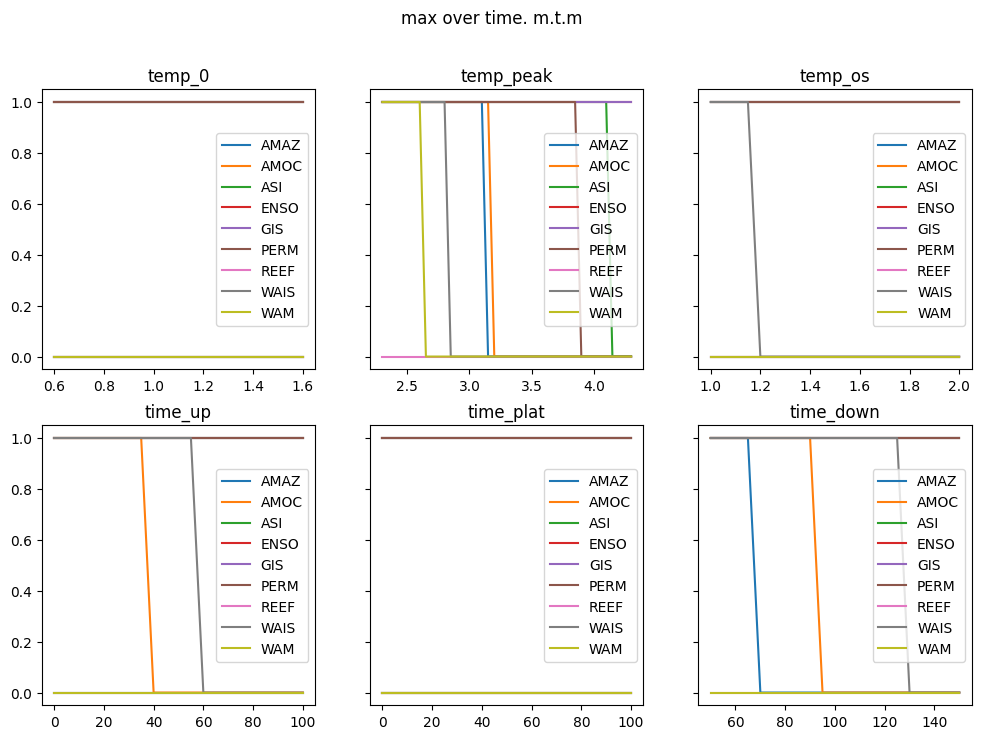

In [285]:
fig,axs = plt.subplots(nrows=2,ncols=3,figsize=(12,8),sharex=False,sharey=True)
sos_threshold=0.1
fig.suptitle("max over time. m.t.m")
TEs=df_TEs.index.to_numpy()
for i in range(6):
    axs[i//3,i%3].set_title(par_files[i])

    for j in range(len(TEs)):
        axs[i//3,i%3].plot(pars[i],
                           (D[i].max(axis=-1).mean(axis=1)<=sos_threshold)[:,j],label=TEs[j])
    axs[i//3,i%3].legend()
    
    # fig.colorbar(ScalarMappable(cmap=cmap, norm=plt.Normalize(pars[i][a], pars[i][b-1])),ax=axs[i//3,i%3])

In [353]:
from matplotlib.patches import Circle, RegularPolygon
from matplotlib.path import Path
from matplotlib.projections import register_projection
from matplotlib.projections.polar import PolarAxes
from matplotlib.spines import Spine
from matplotlib.transforms import Affine2D


def radar_factory(num_vars, frame='circle'):
    """
    Create a radar chart with `num_vars` Axes.

    This function creates a RadarAxes projection and registers it.

    Parameters
    ----------
    num_vars : int
        Number of variables for radar chart.
    frame : {'circle', 'polygon'}
        Shape of frame surrounding Axes.

    """
    # calculate evenly-spaced axis angles
    theta = np.linspace(0, 2*np.pi, num_vars, endpoint=False)

    class RadarTransform(PolarAxes.PolarTransform):

        def transform_path_non_affine(self, path):
            # Paths with non-unit interpolation steps correspond to gridlines,
            # in which case we force interpolation (to defeat PolarTransform's
            # autoconversion to circular arcs).
            if path._interpolation_steps > 1:
                path = path.interpolated(num_vars)
            return Path(self.transform(path.vertices), path.codes)

    class RadarAxes(PolarAxes):

        name = 'radar'
        PolarTransform = RadarTransform

        def __init__(self, *args, **kwargs):
            super().__init__(*args, **kwargs)
            # rotate plot such that the first axis is at the top
            self.set_theta_zero_location('N')

        def fill(self, *args, closed=True, **kwargs):
            """Override fill so that line is closed by default"""
            return super().fill(closed=closed, *args, **kwargs)

        def plot(self, *args, **kwargs):
            """Override plot so that line is closed by default"""
            lines = super().plot(*args, **kwargs)
            for line in lines:
                self._close_line(line)

        def _close_line(self, line):
            x, y = line.get_data()
            # FIXME: markers at x[0], y[0] get doubled-up
            if x[0] != x[-1]:
                x = np.append(x, x[0])
                y = np.append(y, y[0])
                line.set_data(x, y)

        def set_varlabels(self, labels):
            self.set_thetagrids(np.degrees(theta), labels)

        def _gen_axes_patch(self):
            # The Axes patch must be centered at (0.5, 0.5) and of radius 0.5
            # in axes coordinates.
            if frame == 'circle':
                return Circle((0.5, 0.5), 0.5)
            elif frame == 'polygon':
                return RegularPolygon((0.5, 0.5), num_vars,
                                      radius=.5, edgecolor="k")
            else:
                raise ValueError("Unknown value for 'frame': %s" % frame)

        def _gen_axes_spines(self):
            if frame == 'circle':
                return super()._gen_axes_spines()
            elif frame == 'polygon':
                # spine_type must be 'left'/'right'/'top'/'bottom'/'circle'.
                spine = Spine(axes=self,
                              spine_type='circle',
                              path=Path.unit_regular_polygon(num_vars))
                # unit_regular_polygon gives a polygon of radius 1 centered at
                # (0, 0) but we want a polygon of radius 0.5 centered at (0.5,
                # 0.5) in axes coordinates.
                spine.set_transform(Affine2D().scale(.5).translate(.5, .5)
                                    + self.transAxes)
                return {'polar': spine}
            else:
                raise ValueError("Unknown value for 'frame': %s" % frame)

    register_projection(RadarAxes)
    return theta

In [394]:
def local_safety(D,safety_threshold=0.1,
              dimension_kw=dict(year=-1,sample=1)):
    return np.max(D,axis=dimension_kw['year'],keepdims=True).mean(axis=dimension_kw['sample'],keepdims=True)<=safety_threshold

## Plotting spider charts

In [531]:
r_data = np.array([np.max(np.squeeze(local_safety(D[i]))*pars[i].reshape(len(pars[i]),1),axis=0) for i in range(len(popt))])
# # ls = np.squeeze(local_safety(D[i]))
# print(r_data)

In [527]:
folder_out = '../../Figures/Overshoots/perturb_around_baseline/'+baseline+'/'
if not os.path.exists(folder_out):
    os.makedirs(folder_out)

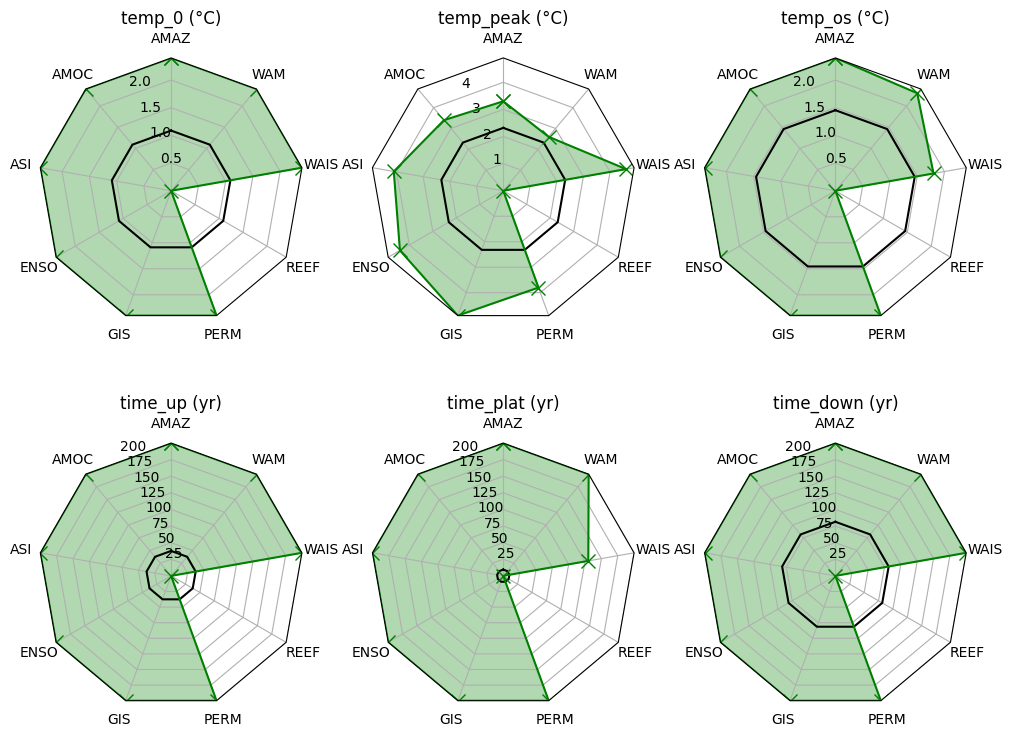

In [536]:
N = len(TEs)#len(popt)
theta = radar_factory(N, frame='polygon')
fig, axs = plt.subplots(figsize=(12, 9),nrows=2,ncols=3,
                            subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.15, top=0.85, bottom=0.05)

units= [' (°C)', ' (yr)']

for i in range(len(popt)):
    axs[i//3,i%3].plot(theta,[popt[i]]*N,color='k')
    axs[i//3,i%3].plot(theta,r_data[i,:],color='g',marker='x',markersize=10)
    axs[i//3,i%3].fill(theta,r_data[i,:],facecolor='g',alpha=0.3,label='_nolegend_')
    axs[i//3,i%3].set_xticks(theta,TEs)
    axs[i//3,i%3].set_ylim(pars[i][0],pars[i][-1])
    # if i==1:
        # axs[i//3,i%3].set_ylim(min(popt[0],popt[2]),pars[i][-1])
    axs[i//3,i%3].set_title(par_files[i] + units[i//3])
# ax.set_varlabels(spoke_labels)
# fig.savefig(folder_out+'six_spiders.png',bbox_inches='tight')

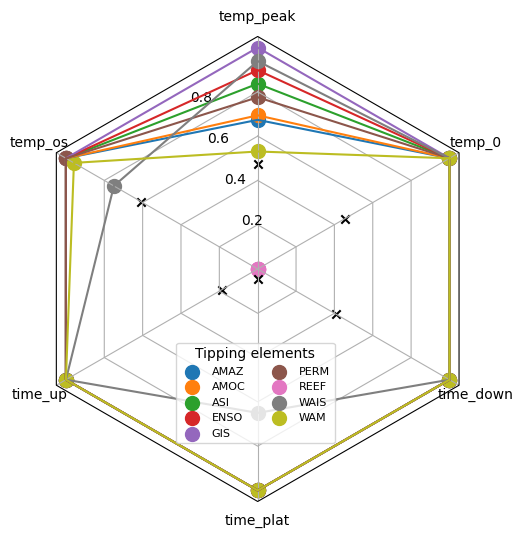

In [529]:
r_normed = np.copy(r_data)
for i in range(len(popt)):
    r_normed[i,:] /= pars[i][-1]

N = len(popt)
theta = radar_factory(N, frame='polygon')
fig, ax = plt.subplots(figsize=(6,6),nrows=1,ncols=1,
                            subplot_kw=dict(projection='radar'))
fig.subplots_adjust(wspace=0.25, hspace=0.20, top=0.85, bottom=0.05)

spoke_labels = par_files

# for ax, (title, case_data) in zip(axs.flat, data):
# ax.set_theta_zero_location(')
ax.set_rgrids([0.2, 0.4, 0.6, 0.8])
# ax.set_title(title, weight='bold', size='medium', position=(0.5, 1.1),
#              horizontalalignment='center', verticalalignment='center')
prop_cycle = plt.rcParams['axes.prop_cycle']
colors = prop_cycle.by_key()['color']
reorder = [5,0,1,2,3,4]
for i in range(len(TEs)):
    # ax.fill(theta[reorder], r_normed[:,i], facecolor=colors[i], alpha=0.1, label='_nolegend_');
    ax.plot(theta[reorder], r_normed[:,i], color=colors[i],label='_nolegend_');
    ax.scatter(theta[reorder], r_normed[:,i], color=colors[i],marker='o',s=100,label=TEs[i]);
ax.set_xticks(theta[reorder],par_files)
# ax.set_ylim(0.01,1)
# ax.set_varlabels(spoke_labels)
ax.legend(loc=(0.325,0.125),ncols=2,title='Tipping elements',fontsize=8)
ax.scatter(theta[reorder],[popt[i]/pars[i][-1] for i in range(N)],color='k',marker='x')
fig.savefig(folder_out+'single_spider.png',bbox_inches='tight')